# Logistic Regression 


This notebook implements a logistic regression as a baseline model to predict death probabilities from clinical and molecular data.




In [1]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

In [2]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1]. drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]


X_test = test_data.iloc[: , :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 445575 lignes, 81 features
   - Test: 56938 lignes
   - Target distribution (train): {0: 249063, 1: 196512}


In [5]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'LogisticRegression'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    if MODEL_TYPE == 'LogisticRegression':
        trainer.tune_logistic_regression(
            param_grid={
                'C': [0.01, 0.1, 1, 10],
                'penalty': ['l2'],
                'solver': ['liblinear'],
                'class_weight': [None, 'balanced']
            },
            method='grid',
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'RandomForest':
        trainer.tune_random_forest(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 10, None],
                'min_samples_leaf': [1, 2],
                'max_features': ['sqrt']
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'XGBoost':
        trainer.tune_xgboost(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7],
                'learning_rate': [0.01, 0.1],
                'subsample': [0.6, 0.8, 1.0]
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle LogisticRegression trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (GRID)
   Modèle: logistic_regression_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['C', 'penalty', 'solver', 'class_weight']
Fitting 5 folds for each of 8 candidates, totalling 40 fits


/home/mouad-sehli/datascience/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/mouad-sehli/datascience/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/mouad-sehli/datascience/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed 


✓ Meilleurs paramètres trouvés:
   - C:  0.01
   - class_weight:  balanced
   - penalty:  l2
   - solver:  liblinear
   - Best CV Score (roc_auc): 0.8064

📊 Résultats:
   - Train Accuracy: 0.7304
   - Test Accuracy:  0.7045
✓ Modèle sauvegardé: models/logistic_regression_tuned.pkl
✓ Paramètres sauvegardés: models/logistic_regression_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: logistic_regression_tuned
   Paramètres: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}



📊 ÉVALUATION SUR LE TEST SET

🔍 ÉVALUATION COMPLÈTE:  logistic_regression_tuned_test
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.7045
   Balanced_Accuracy        : 0.7038
   Precision                : 0.6666
   Recall_Sensitivity       : 0.6966
   Specificity              : 0.7111
   F1_Score                 : 0.6813
   Matthews_Corr_Coef       : 0.4065
   Cohen_Kappa              : 0.4061

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.7746
   PR_AUC                   : 0.7275
   Brier_Score              : 0.1935
   Log_Loss                 : 0.5697

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.74      0.71      0.72     31128
    Classe 1       0.67      0.70      0.68     25810

    accuracy                           0.70     56938
   macro avg       0.70      0.70      0.70     56938
we

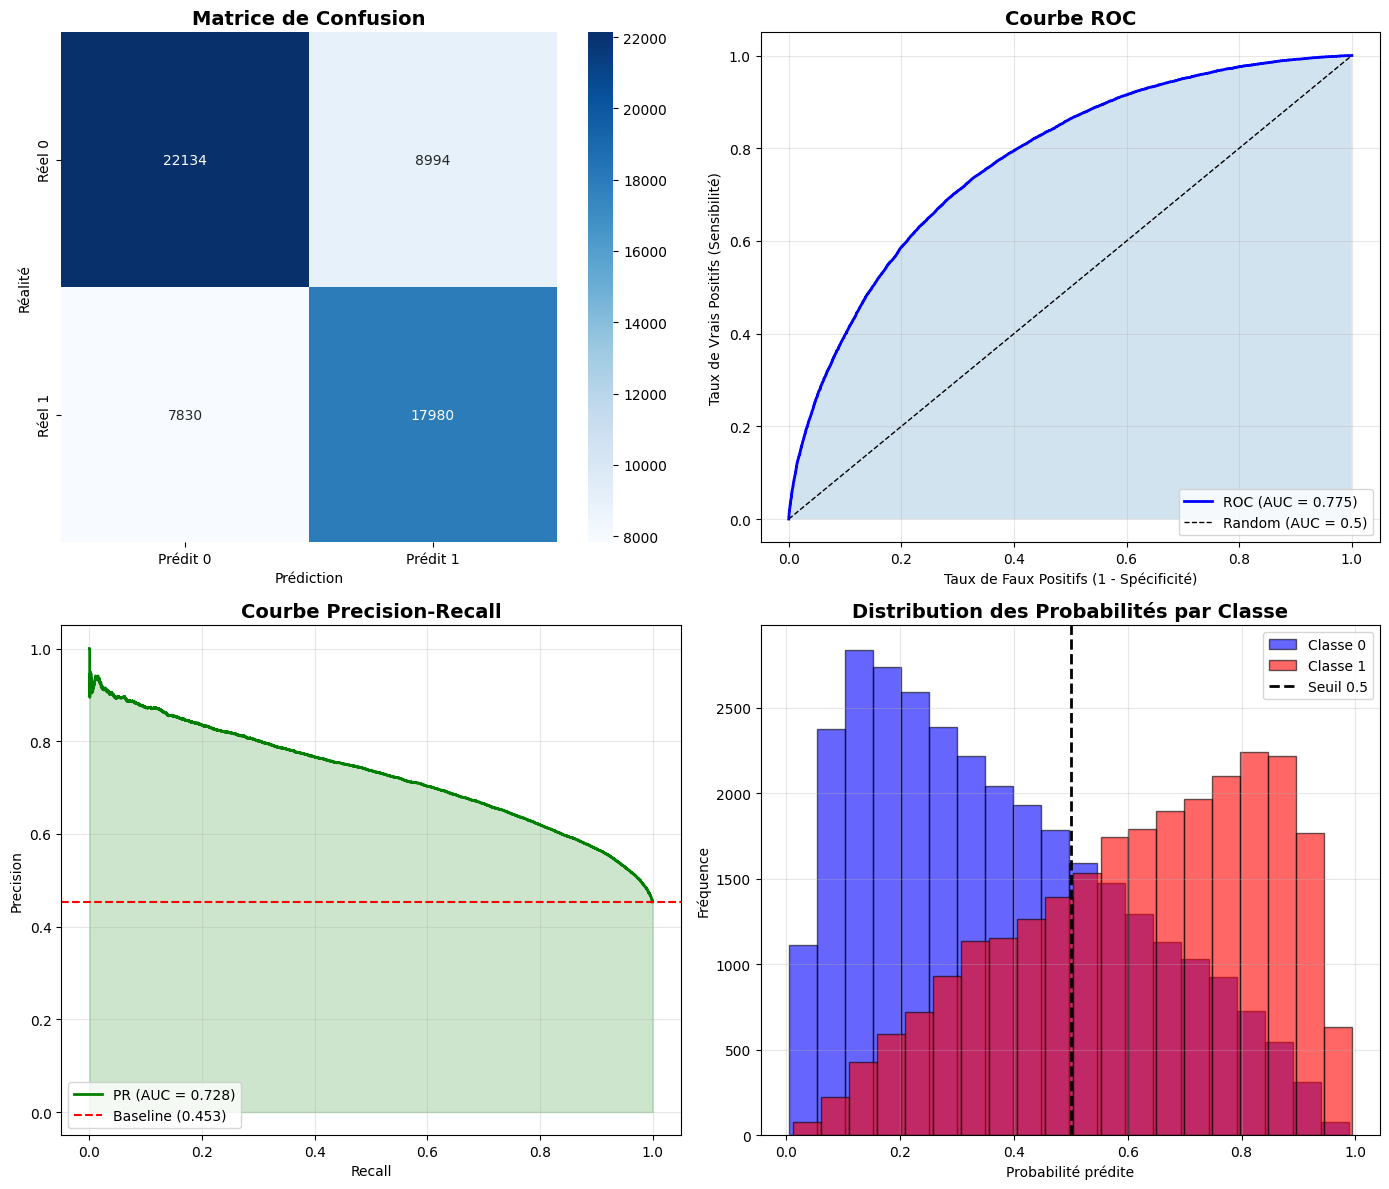

In [6]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TEST SET
# =============================================================================


# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

## Logistic Regression Results Analysis

### Model Performance
- **ROC-AUC: 0.777** — Good discriminative capacity to distinguish patient pairs
- **Accuracy: 70.5%** — Balanced performance between classes
- **Brier Score: 0.193** — The lowest among all models, indicating already well-calibrated probabilities

Logistic regression directly optimizes log-likelihood, which naturally produces well-calibrated probabilities. This is why the Brier Score is satisfactory without requiring post-hoc calibration.

However, it is a linear model that may not capture complex non-linear relationships between clinical/molecular features.

